# Algoritmo de clasificación vecinos más cercanos KNN

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [10]:
# Configurar estilo
plt.style.use('default')
sns.set_palette("husl")
np.random.seed(42)

# 1. Generación de Datos Sintéticos

## Creamos un dataset simple de 2 características para facilitar la visualización.


In [12]:
X, y = make_classification(
    n_samples=200,           # 200 muestras
    n_features=2,            # 2 características
    n_redundant=0,           # sin características redundantes
    n_clusters_per_class=1,  # un cluster por clase
    random_state=42
)

# Crear DataFrame para visualización
df = pd.DataFrame(X, columns=['Característica 1', 'Característica 2'])
df['Clase'] = y

print("DATOS GENERADOS")
print("=" * 40)
print(f"Número de muestras: {len(df)}")
print(f"Número de características: {2}")
print(f"Clases: {np.unique(y)}")
print(f"\nDistribución de clases:")
print(df['Clase'].value_counts())
print(f"\nPrimeras 5 filas:")
print(df.head())

DATOS GENERADOS
Número de muestras: 200
Número de características: 2
Clases: [0 1]

Distribución de clases:
Clase
1    100
0    100
Name: count, dtype: int64

Primeras 5 filas:
   Característica 1  Característica 2  Clase
0         -0.872929          0.013042      1
1          1.312935          2.770534      1
2          2.340428          2.420996      1
3          2.294548         -0.404380      1
4          0.944105          0.477241      1


# 2. Visualización de los Datos
 
## Observamos cómo se distribuyen las dos clases en el espacio de características.


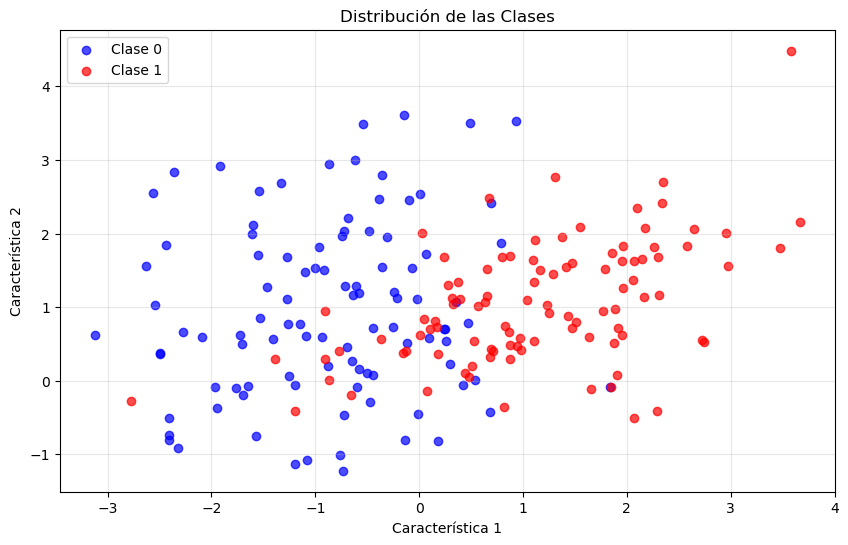

In [14]:
plt.figure(figsize=(10, 6))
plt.scatter(X[y==0, 0], X[y==0, 1], color='blue', alpha=0.7, label='Clase 0')
plt.scatter(X[y==1, 0], X[y==1, 1], color='red', alpha=0.7, label='Clase 1')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.title('Distribución de las Clases')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. División en Entrenamiento y Prueba

## Dividir datos (80% entrenamiento, 20% prueba)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("DIVISIÓN DE DATOS")
print("=" * 40)
print(f"Entrenamiento: {len(X_train)} muestras")
print(f"Prueba: {len(X_test)} muestras")

DIVISIÓN DE DATOS
Entrenamiento: 160 muestras
Prueba: 40 muestras


# 4. Entrenamiento del Modelo k-NN
 
## El algoritmo k-NN no tiene una fase de entrenamiento tradicional. Simplemente almacena los datos de entrenamiento para usarlos en la predicción. Vamos a crear un modelo con k=3, es decir, 3 vecinos cercanos, donde recordemos que:


## 1. Para clasificar un nuevo punto, busca los k puntos de entrenamiento más cercanos
## 2. Vota por la clase más frecuente entre esos k vecinos
## 3. Asigna esa clase al nuevo punto


In [18]:
knn = KNeighborsClassifier(n_neighbors=3)

# "Entrenar" el modelo (almacena los datos)
knn.fit(X_train, y_train)

print("MODELO k-NN CREADO")
print("=" * 40)
print(f"k (número de vecinos): {knn.n_neighbors}")
print(f"Métrica de distancia: {knn.metric}")

MODELO k-NN CREADO
k (número de vecinos): 3
Métrica de distancia: minkowski


# 5. Predicciones y Evaluación

## Iniciamos prediciendo en el conjunto de prueba

In [20]:
y_pred = knn.predict(X_test)


accuracy = accuracy_score(y_test, y_pred) # Calcular exactitud

print("EVALUACIÓN DEL MODELO")
print("=" * 40)
print(f"Exactitud (Accuracy): {accuracy:.4f}")
print(f"\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))

EVALUACIÓN DEL MODELO
Exactitud (Accuracy): 0.8750

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.94      0.80      0.86        20
           1       0.83      0.95      0.88        20

    accuracy                           0.88        40
   macro avg       0.88      0.88      0.87        40
weighted avg       0.88      0.88      0.87        40




# 6. Matriz de Confusión

## La matriz de confusión muestra dónde el modelo acierta y dónde se equivoca.


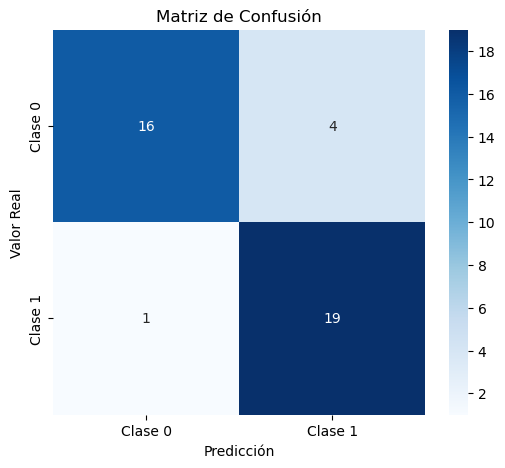

In [22]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Clase 0', 'Clase 1'],
            yticklabels=['Clase 0', 'Clase 1'])
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()

# 7. Visualización de la frontera de decisión

## Creamos un gráfico para visualizar cómo el clasificador separa las dos clases.


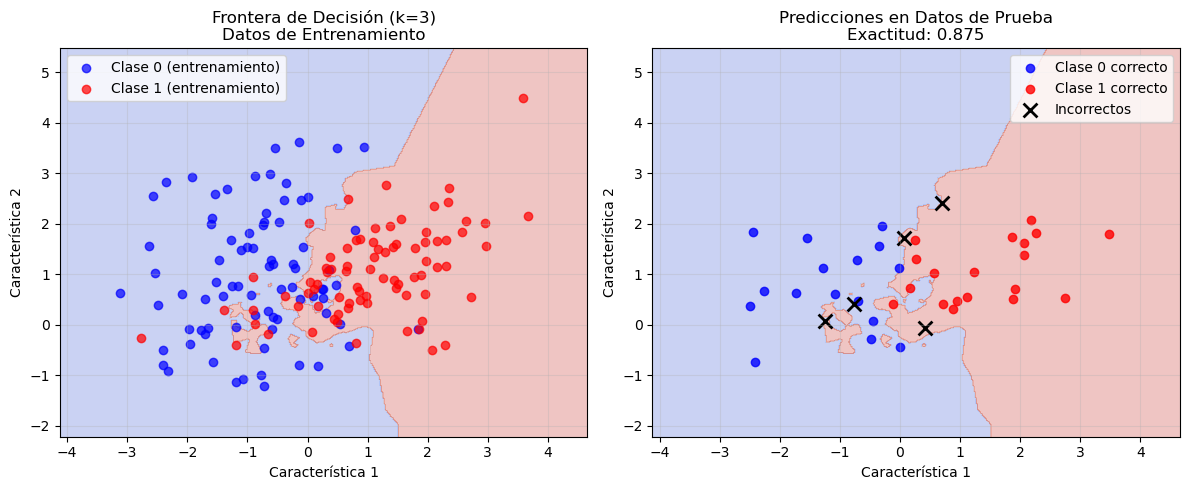

In [26]:
h = 0.02  # paso de la malla
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(12, 5))

# Subplot 1: Datos de entrenamiento con frontera
plt.subplot(1, 2, 1)
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1], 
            color='blue', alpha=0.7, label='Clase 0 (entrenamiento)')
plt.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1], 
            color='red', alpha=0.7, label='Clase 1 (entrenamiento)')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.title(f'Frontera de Decisión (k={knn.n_neighbors})\nDatos de Entrenamiento')
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: Datos de prueba con predicciones
plt.subplot(1, 2, 2)
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
correctos = (y_pred == y_test)
incorrectos = ~correctos
plt.scatter(X_test[correctos & (y_test==0), 0], X_test[correctos & (y_test==0), 1], 
            color='blue', marker='o', alpha=0.8, label='Clase 0 correcto')
plt.scatter(X_test[correctos & (y_test==1), 0], X_test[correctos & (y_test==1), 1], 
            color='red', marker='o', alpha=0.8, label='Clase 1 correcto')
plt.scatter(X_test[incorrectos, 0], X_test[incorrectos, 1], 
            color='black', marker='x', s=100, linewidths=2, label='Incorrectos')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.title(f'Predicciones en Datos de Prueba\nExactitud: {accuracy:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 8. Efecto del Parámetro k

# Ahora probemos diferentes valores de k para ver cómo afectan a la clasificación. Los tomamos de manera aleatoria, sin aplicar ningún tipo de logica matemática en su escogencia.

k =  1 → Exactitud: 0.8750
k =  3 → Exactitud: 0.8750
k =  5 → Exactitud: 0.8500
k =  7 → Exactitud: 0.8500
k =  9 → Exactitud: 0.8500
k = 11 → Exactitud: 0.8500
k = 15 → Exactitud: 0.8500
k = 21 → Exactitud: 0.9000


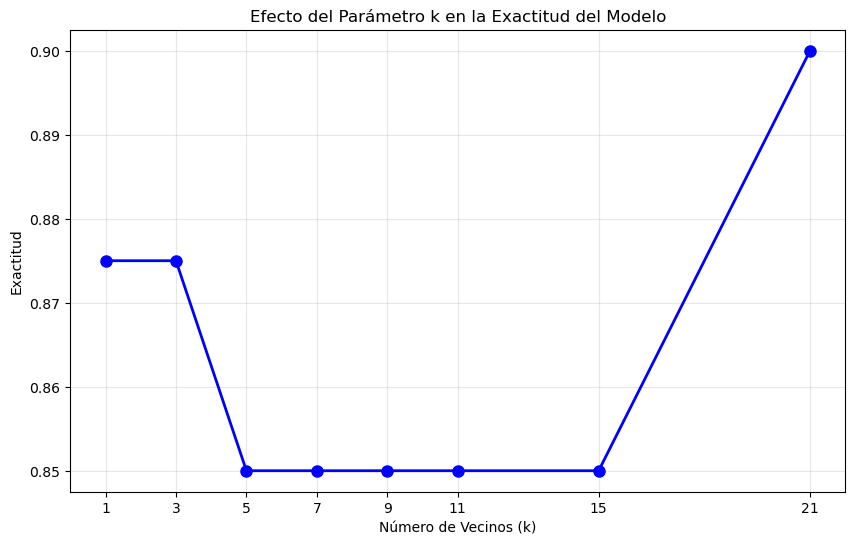


Mejor valor de k: 21 con exactitud: 0.9000


In [30]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
accuracies = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    y_pred_temp = knn_temp.predict(X_test)
    acc = accuracy_score(y_test, y_pred_temp)
    accuracies.append(acc)
    print(f"k = {k:2d} → Exactitud: {acc:.4f}")

# Graficar resultados
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Número de Vecinos (k)')
plt.ylabel('Exactitud')
plt.title('Efecto del Parámetro k en la Exactitud del Modelo')
plt.grid(True, alpha=0.3)
plt.xticks(k_values)
plt.show()

# Encontrar el mejor k
best_k = k_values[np.argmax(accuracies)]
print(f"\nMejor valor de k: {best_k} con exactitud: {max(accuracies):.4f}")


 # 9. Predicción en Nuevos Datos

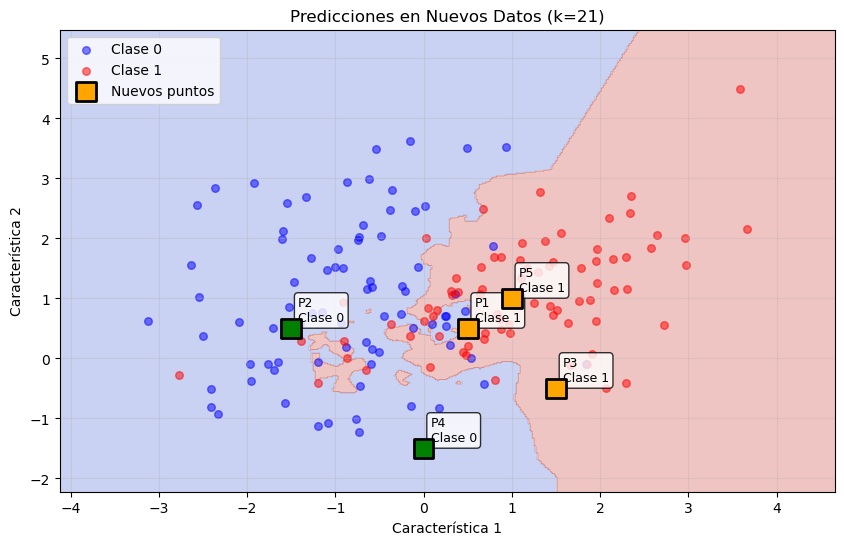


PREDICCIONES EN NUEVOS DATOS
Punto 1: (0.50, 0.50) → Clase 1
Punto 2: (-1.50, 0.50) → Clase 0
Punto 3: (1.50, -0.50) → Clase 1
Punto 4: (0.00, -1.50) → Clase 0
Punto 5: (1.00, 1.00) → Clase 1


In [32]:
nuevos_datos = np.array([
    [0.5, 0.5],   # Punto central
    [-1.5, 0.5],  # Cerca de clase 0
    [1.5, -0.5],  # Cerca de clase 1
    [0, -1.5],    # Zona inferior
    [1, 1]        # Zona superior
])


knn_mejor = KNeighborsClassifier(n_neighbors=best_k)# acá le indicamos que tome el mejor modelo
knn_mejor.fit(X_train, y_train)
predicciones = knn_mejor.predict(nuevos_datos)

plt.figure(figsize=(10, 6))

# Señalamos la frontera de decisión dentro del conjunto de datos
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1], 
            color='blue', alpha=0.5, s=30, label='Clase 0')
plt.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1], 
            color='red', alpha=0.5, s=30, label='Clase 1')

# Marcamos los nuevos puntos
colors = ['green' if p == 0 else 'orange' for p in predicciones]
plt.scatter(nuevos_datos[:, 0], nuevos_datos[:, 1], 
            color=colors, s=200, edgecolors='black', linewidth=2,
            marker='s', label='Nuevos puntos', zorder=5)

# Asignamos etiquetas para los nuevos puntos
for i, (x, y) in enumerate(nuevos_datos):
    plt.annotate(f'P{i+1}\nClase {predicciones[i]}', 
                (x, y), xytext=(5, 5), textcoords='offset points',
                fontsize=9, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.title(f'Predicciones en Nuevos Datos (k={best_k})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Se muestran las predicciones en una tabla al final de la gráfica
print("\nPREDICCIONES EN NUEVOS DATOS")
print("=" * 40)
for i, (punto, pred) in enumerate(zip(nuevos_datos, predicciones)):
    print(f"Punto {i+1}: ({punto[0]:.2f}, {punto[1]:.2f}) → Clase {pred}")

# 10. Ejercicio

## El dataset wine-quality-white contiene 4,898 muestras de vinos portugueses de la variedad "Vinho Verde", cada una caracterizada por 11 variables físico-químicas que describen las propiedades del vino. Estas variables incluyen concentraciones de componentes como el alcohol, la acidez fija, la acidez volátil, el ácido cítrico, el azúcar residual, los cloruros, el dióxido de azufre libre y total, la densidad, el pH y los sulfatos, todas medidas con precisión analítica. Cada muestra está etiquetada con una variable objetivo denominada Class que representa la calidad sensorial del vino, evaluada en una escala ordinal del 1 al 10 por un panel de expertos catadores.

In [78]:
# Cargar dataset Wine Quality
wine = fetch_openml(name='wine-quality-white', version=1, as_frame=True)
df = wine.frame


In [80]:
df

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,Class
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,4
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,4
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,4
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,4
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,4
...,...,...,...,...,...,...,...,...,...,...,...,...
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,4
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,3
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,4
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,5


# Responda:

## 1. Análisis Exploratorio 

## Calcule la matriz de correlación. ¿Qué variables tienen mayor correlación con la calidad del vino? ¿Qué pares de variables muestran alta correlación entre sí?

## La calidad del vino originalmente es una variable ordinal de 1 a 10. Pero para clasificación binaria, queremos que el modelo aprenda a distinguir entre:

### * Vinos de mala calidad (calidad < 6) → Clase 0.

### * Vinos de buena calidad (calidad ≥ 6) → Clase 1.

## Adapte los datos para que el modelo de aprendizaje distinga entre estas dos categorías.

## Divida los datos en conjuntos de entrenamiento (70%) y prueba (30%), manteniendo la proporción de clases (estratificación).

## 2. Implementación y Evaluación Base con k-NN

## Implemente el clasificador k -NN con $\$ \mathrm{k}=5 \$$ y métrica de distancia euclidiana. Calcule y analice:

### a) La matriz de confusión para el conjunto de prueba.

### b) Para cada clase, calcule: Precisión, Recall, F1-Score y Soporte.

### c) Calcule los promedios Macro y Weighted para precisión, recall y F1-Score.

### d) La exactitud (accuracy) global del modelo.

### e) Interprete cada métrica en el contexto del problema: ¿Qué significan un alto recall en la clase "bueno"? ¿Qué implicaría un alto precision en la clase "malo"?

## 3. Evaluación con Diferentes Métricas de Distancia

## k -NN permite utilizar diferentes métricas de distancia. Evalúe el rendimiento del modelo con $\$ \mathrm{k}=5 \$$ para las siguientes métricas:

### - Distancia Euclidiana: \$d(\mathbf\{x\}, \mathbf\{y\}) = \sqrt\{\sum_\{i=1\}^n (x_i - y_i)^2\}\$

### - Distancia Manhattan: \$d(\mathbf\{x\}, \mathbf\{y\}) = \sum_\{i=1\}^n |x_i - y_i|\$

### - Distancia de Minkowski con $p=3$ : $d(\mathbf{x}, \mathbf{y}) = \left(\sum_{i=1}^n |x_i - y_i|^p\right)^{1/p}$

## Para cada métrica, calcule y presente en una tabla comparativa:

### - Accuracy

### - Precision Macro, Recall Macro, F1 Macro

### - Precision Weighted, Recall Weighted, F1 Weighted

### ¿Qué métrica de distancia produce mejores resultados? ¿Por qué cree que ocurre esto?

## 4. Optimización del Parámetro k

## Realice una búsqueda sistemática del mejor valor de $k$ para el modelo k-NN (usando distancia euclidiana):

### a) Evalúe valores de $k$ desde 1 hasta 50 (impares).

### b) Para cada $k$, calcule la exactitud promedio mediante validación cruzada de 5 folds.

### c) Grafique $k$ vs Accuracy promedio. Identifique el valor óptimo de $k$.

### d) Con el $k$ óptimo encontrado, entrene el modelo final y calcule todas las métricas de evaluación en el conjunto de prueba.

### e) Compare los resultados con el modelo base ($k=5$). ¿Mejoró el rendimiento? ¿En qué métricas se nota más la mejora?

## 5 Selección del Mejor Modelo y Análisis de Errores

## Considere todas las combinaciones de métricas de distancia y valores de $k$ exploradas en las preguntas anteriores. Determine:

###  a) ¿Cuál es la mejor combinación (métrica + k) según la exactitud (accuracy)? ¿Y según el F1-Score macro?

###  b) Para el mejor modelo encontrado, analice los errores de clasificación:

###  ¿Cuántos falsos positivos y falsos negativos tiene?
###  ¿Qué tipo de error es más frecuente? ¿Es esto aceptable en el contexto de vinos?

### c) Proponga una posible mejora al modelo que podría reducir los errores de clasificación (por ejemplo: selección de características, pesos por distancia, etc.)

###  d) Conclusión final: ¿Recomendaría usar este modelo para clasificar la calidad del vino? Justifique su respuesta basándose en las métricas obtenidas.